# Anomaliedetectie: fraude opsporen met een autoencoder

**Topic 2 — PXL · autoencoders op tabulaire data**

---

## Het probleem met fraude

Fraudedetectie heeft een eigenschap die de meeste machine learning-cursussen niet behandelen:
**je hebt bijna geen voorbeelden van wat je zoekt.** In onze dataset is nog geen 1% van de
transacties frauduleus. En de fraude die je in je data hébt, is de fraude van *gisteren* —
morgen verzinnen ze iets nieuws.

Een gewone classifier leren "dit is fraude" heeft daardoor twee problemen:

1. Hij ziet zo weinig fraude dat hij hem nauwelijks leert herkennen.
2. Hij herkent alleen de trucs die al in de data zaten.

## De omkering

Daarom draaien we de vraag om. In plaats van te leren hoe **fraude** eruitziet, leren we
heel precies hoe **normaal** eruitziet. Alles wat daar niet in past, is verdacht.

> Een bankmedewerker die duizend gewone transacties per dag ziet, hoeft niet te weten hoe fraude
> eruitziet om te merken dat er iets vreemds langskomt.

Het gereedschap daarvoor is de **autoencoder**: een neuraal netwerk dat je traint om zijn eigen
invoer weer uit te spugen. Klinkt nutteloos — tot je het een flessenhals geeft.

## Wat gaan we doen?

1. De fraudedataset bekijken en zien hoe scheef hij is.
2. Begrijpen wat een autoencoder is en waarom dat werkt voor anomalieën.
3. Er één bouwen en trainen — **alleen op normale transacties**.
4. De reconstructiefout gebruiken als anomaliescore.
5. Een drempel kiezen, en zien wat die keuze kost.
6. Controleren of dat neurale netwerk wel nodig was.
7. Uitzoeken *waarom* een transactie gemarkeerd werd.

## 0. Setup

In [1]:
# --- standaard data-stack ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- scikit-learn: voorbewerking, baselines, evaluatie ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay,
)

# --- het model ---
import torch
import torch.nn as nn

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

# Eén vaste seed voor de hele notebook, zodat jouw output gelijk is aan die op het scherm.
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("numpy ", np.__version__)
print("pandas", pd.__version__)
print("torch ", torch.__version__)

numpy  2.5.3
pandas 3.0.5
torch  2.14.0


## 1. De dataset

We gebruiken de bekende **Credit Card Fraud**-dataset: echte kaarttransacties van Europese
kaarthouders uit september 2013.

Om privacyredenen zijn de oorspronkelijke kolommen (winkel, tijdstip, locatie, …) niet
vrijgegeven. In plaats daarvan bevat de dataset **28 anonieme componenten `V1` tot `V28`**,
het resultaat van een PCA-transformatie op de echte features. Alleen `Amount` (het bedrag)
is herkenbaar gebleven.

| | |
|---|---|
| `V1` … `V28` | anonieme componenten, al genormaliseerd door de PCA |
| `Amount` | het transactiebedrag in euro |
| `Class` | `0` = normaal, `1` = fraude |

We werken met een compacte selectie: alle 492 fraudegevallen plus 60.000 willekeurige normale
transacties. Die staat lokaal gecacht, dus je hebt geen internet nodig.

In [2]:
# Het bestand is gemaakt door haal_data.py (zie README). Geen internet nodig.
bestand = Path("data/creditcard-subset.parquet")
if not bestand.exists():
    raise FileNotFoundError(
        "Dataset niet gevonden. Draai eerst eenmalig:  .venv/bin/python haal_data.py"
    )

df = pd.read_parquet(bestand)
print(f"{df.shape[0]:,} transacties x {df.shape[1]} kolommen")
display(df.head())

60,492 transacties x 30 kolommen


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.949651,-0.168557,0.253949,1.026223,-0.099157,0.166770,0.069750,-0.006161,-0.243838,0.101481,...,0.016699,-0.247195,-0.226578,-0.516095,0.480243,-0.461846,0.008425,0.040348,150.00,0
1,-10.930244,6.000305,-10.746348,1.319919,-4.576451,-1.194886,-2.561206,5.249172,2.739458,3.342491,...,-0.828865,-1.306951,-0.838345,-1.683528,0.607446,-0.420511,-0.655371,-0.936925,89.99,0
2,1.497429,-1.149740,0.572843,-1.520871,-1.645849,-0.444841,-1.320183,0.096800,-1.704024,1.639949,...,-0.364730,-0.802357,0.154808,-0.097475,0.088312,-0.400266,0.028585,0.011062,5.00,0
3,2.116635,0.174639,-2.036012,1.146078,0.879271,-0.569977,0.562149,-0.308889,0.385604,0.284724,...,-0.032021,0.125162,-0.115920,-1.078120,0.575945,-0.421192,-0.019390,-0.075552,1.00,0
4,-1.047812,-0.223278,1.837459,-2.393252,-1.621007,-0.934938,-0.970229,0.544069,-2.037873,0.675299,...,-0.024973,0.085703,-0.224490,0.320916,0.377270,-0.162897,0.178626,0.032847,8.10,0


In [3]:
# Hoe scheef is deze dataset eigenlijk?
aantal = df["Class"].value_counts()
aandeel = df["Class"].mean()

print(f"normale transacties : {aantal[0]:>6,}")
print(f"fraudegevallen      : {aantal[1]:>6,}")
print(f"aandeel fraude      : {aandeel:.3%}")
print()
print("Even stilstaan bij wat dat betekent voor je evaluatie:")
print(f"een model dat ALTIJD 'geen fraude' zegt, heeft {1 - aandeel:.2%} accuracy.")
print("Accuracy is hier dus een waardeloze maat. Daar komen we in §5 op terug.")

normale transacties : 60,000
fraudegevallen      :    492
aandeel fraude      : 0.813%

Even stilstaan bij wat dat betekent voor je evaluatie:
een model dat ALTIJD 'geen fraude' zegt, heeft 99.19% accuracy.
Accuracy is hier dus een waardeloze maat. Daar komen we in §5 op terug.


### Waarom `Amount` aparte aandacht nodig heeft

De `V`-kolommen komen uit een PCA en staan al netjes rond nul. `Amount` niet: de meeste
transacties zijn klein, een enkele is enorm. Zo'n scheve verdeling laat één uitschieter van
€25.000 het hele netwerk domineren.

De standaardoplossing is een **logaritme**: die drukt de staart in zonder de volgorde te
veranderen.

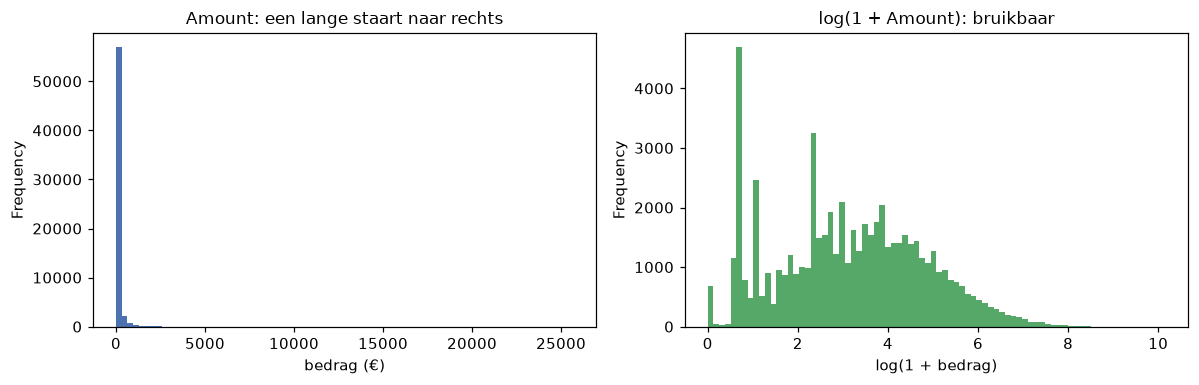

grootste bedrag: € 25,691.16   mediaan: € 22.00
We gebruiken log1p: dat is log(1 + x), zodat een bedrag van € 0 geen probleem geeft.


In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
df["Amount"].plot.hist(bins=80, ax=a, color="#4C72B0")
a.set_title("Amount: een lange staart naar rechts", fontsize=11)
a.set_xlabel("bedrag (€)")

np.log1p(df["Amount"]).plot.hist(bins=80, ax=b, color="#55A868")
b.set_title("log(1 + Amount): bruikbaar", fontsize=11)
b.set_xlabel("log(1 + bedrag)")

plt.tight_layout()
plt.show()

print(f"grootste bedrag: € {df['Amount'].max():,.2f}   mediaan: € {df['Amount'].median():,.2f}")
print("We gebruiken log1p: dat is log(1 + x), zodat een bedrag van € 0 geen probleem geeft.")

---

## 2. Wat is een autoencoder?

Een autoencoder is een neuraal netwerk met een opvallende opdracht: **geef exact terug wat je
binnenkrijgt.** Stop er een transactie in, en er moet dezelfde transactie uitkomen.

Dat lijkt zinloos — tot je ziet hoe hij gebouwd is. Midden in het netwerk zit een **flessenhals**:
een laag die veel smaller is dan de invoer. Alle informatie moet daar doorheen geperst worden.

Het netwerk kan dus niet valsspelen door de invoer te onthouden. Het moet leren **samenvatten**:
wat zijn de paar getallen die genoeg zijn om deze transactie weer op te bouwen?

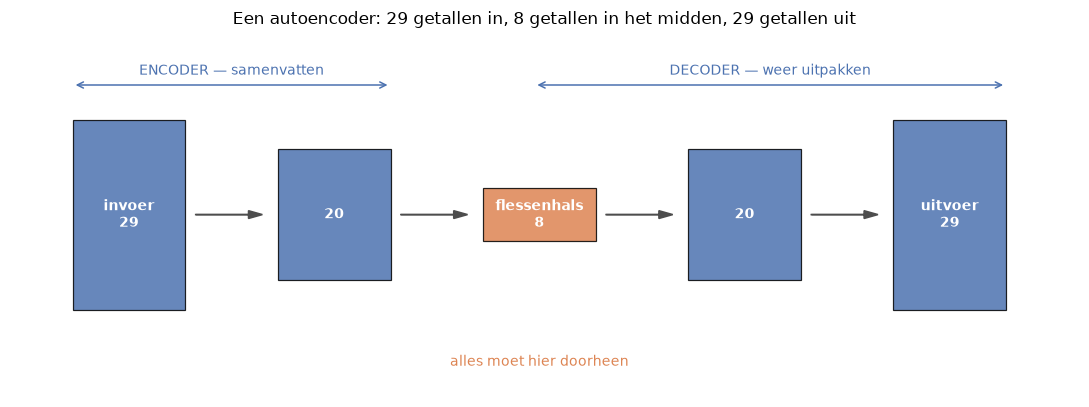

In [5]:
# Een tekening van wat we straks gaan bouwen.
lagen = [("invoer\n29", 29), ("20", 20), ("flessenhals\n8", 8), ("20", 20), ("uitvoer\n29", 29)]

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (label, breedte) in enumerate(lagen):
    hoogte = breedte / 29 * 2.2
    kleur = "#DD8452" if k == 2 else "#4C72B0"
    ax.add_patch(plt.Rectangle((k * 2, -hoogte / 2), 1.1, hoogte,
                               facecolor=kleur, alpha=0.85, edgecolor="black", lw=0.8))
    ax.text(k * 2 + 0.55, 0, label, ha="center", va="center", color="white",
            fontsize=9, fontweight="bold")
    if k < len(lagen) - 1:
        ax.arrow(k * 2 + 1.2, 0, 0.65, 0, head_width=0.09, color="0.3",
                 length_includes_head=True)

ax.annotate("", xy=(3.1, 1.5), xytext=(0, 1.5),
            arrowprops=dict(arrowstyle="<->", color="#4C72B0"))
ax.text(1.55, 1.62, "ENCODER — samenvatten", ha="center", fontsize=9, color="#4C72B0")
ax.annotate("", xy=(9.1, 1.5), xytext=(4.5, 1.5),
            arrowprops=dict(arrowstyle="<->", color="#4C72B0"))
ax.text(6.8, 1.62, "DECODER — weer uitpakken", ha="center", fontsize=9, color="#4C72B0")
ax.text(4.55, -1.75, "alles moet hier doorheen", ha="center", fontsize=9, color="#DD8452")

ax.set_xlim(-0.6, 9.8); ax.set_ylim(-2.1, 2.1); ax.axis("off")
ax.set_title("Een autoencoder: 29 getallen in, 8 getallen in het midden, 29 getallen uit",
             fontsize=11)
plt.tight_layout()
plt.show()

### En waarom vindt dat anomalieën?

Hier komt de truc. We trainen de autoencoder **uitsluitend op normale transacties**.

Hij wordt dus heel goed in precies één ding: normale transacties samenvatten en weer uitpakken.
Stop je er daarna een frauduleuze transactie in, dan gebeurt er iets nuttigs: die past niet in
het patroon dat hij geleerd heeft, dus de reconstructie mislukt.

Het verschil tussen wat erin ging en wat eruit komt — de **reconstructiefout** — is onze
anomaliescore:

```
   normale transactie  ─►  [autoencoder]  ─►  bijna hetzelfde   ─►  kleine fout  ─►  ok
   frauduleuze trans.  ─►  [autoencoder]  ─►  iets heel anders  ─►  grote fout   ─►  alarm
```

> **Let op wat we hier níét doen:** we vertellen het model nergens wat fraude is. De labels
> gebruiken we alleen om achteraf te *controleren* hoe goed het werkt, en om een drempel te
> kiezen. Dat is precies waarom deze aanpak ook nieuwe, nog onbekende fraudepatronen kan
> oppikken.

---

## 3. De data klaarmaken

Drie stappen, en bij elke stap is er iets om op te letten.

In [6]:
# --- (a) Features en label scheiden, Amount temmen ---
X = df.drop(columns="Class").copy()
y = df["Class"].values
X["Amount"] = np.log1p(X["Amount"])          # de scheve staart indrukken (zie §1)

# --- (b) Splitsen. stratify houdt het fraudepercentage in beide helften gelijk;
#         zonder dat kun je zomaar een testset zonder fraude krijgen. ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y,
)

# --- (c) Schalen. LET OP: de scaler wordt gefit op ALLEEN de normale transacties
#         uit de trainset. Dat is geen slordigheid maar de kern van de aanpak:
#         het model mag niets over de fraude weten, ook niet via het gemiddelde. ---
scaler = StandardScaler().fit(X_train[y_train == 0])

naar_tensor = lambda d: torch.tensor(scaler.transform(d), dtype=torch.float32)
train_normaal = naar_tensor(X_train[y_train == 0])   # hierop trainen we
test_alles    = naar_tensor(X_test)                  # hierop evalueren we

print(f"trainset  : {len(X_train):,} transacties, waarvan {y_train.sum()} fraude")
print(f"  -> we trainen op {len(train_normaal):,} NORMALE transacties, de fraude gooien we weg")
print(f"testset   : {len(X_test):,} transacties, waarvan {y_test.sum()} fraude")
print(f"features  : {X.shape[1]}")

trainset  : 42,344 transacties, waarvan 344 fraude
  -> we trainen op 42,000 NORMALE transacties, de fraude gooien we weg
testset   : 18,148 transacties, waarvan 148 fraude
features  : 29


---

## 4. De autoencoder bouwen en trainen

In [7]:
n_features = train_normaal.shape[1]

# 29 -> 20 -> 8 -> 20 -> 29. Symmetrisch, zoals in de tekening hierboven.
torch.manual_seed(RANDOM_STATE)
autoencoder = nn.Sequential(
    # encoder: samenvatten
    nn.Linear(n_features, 20), nn.ReLU(),
    nn.Linear(20, 8),          nn.ReLU(),
    # decoder: weer uitpakken
    nn.Linear(8, 20),          nn.ReLU(),
    nn.Linear(20, n_features),          # geen activatie: de uitvoer mag elk getal zijn
)

print(autoencoder)
print(f"\naantal parameters: {sum(p.numel() for p in autoencoder.parameters()):,}")

Sequential(
  (0): Linear(in_features=29, out_features=20, bias=True)
  (1): ReLU()
  (2): Linear(in_features=20, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=20, bias=True)
  (5): ReLU()
  (6): Linear(in_features=20, out_features=29, bias=True)
)

aantal parameters: 1,557


In [8]:
# De verliesfunctie is het hart van het idee: vergelijk de uitvoer met de INVOER.
# Er komt nergens een label aan te pas.
verlies_functie = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)

lader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(train_normaal), batch_size=256, shuffle=True,
)

geschiedenis = []
for epoch in range(30):
    autoencoder.train()
    totaal = 0.0
    for (batch,) in lader:
        optimizer.zero_grad()
        reconstructie = autoencoder(batch)
        verlies = verlies_functie(reconstructie, batch)   # <- invoer == doel
        verlies.backward()
        optimizer.step()
        totaal += verlies.item() * len(batch)
    geschiedenis.append(totaal / len(train_normaal))
    if epoch % 5 == 0 or epoch == 29:
        print(f"epoch {epoch:2d}   gemiddeld verlies {geschiedenis[-1]:.4f}")

autoencoder.eval()   # eval-modus: altijd doen voor je gaat voorspellen

epoch  0   gemiddeld verlies 0.9459


epoch  5   gemiddeld verlies 0.6145


epoch 10   gemiddeld verlies 0.5753


epoch 15   gemiddeld verlies 0.5542


epoch 20   gemiddeld verlies 0.5342


epoch 25   gemiddeld verlies 0.5220


epoch 29   gemiddeld verlies 0.5145


Sequential(
  (0): Linear(in_features=29, out_features=20, bias=True)
  (1): ReLU()
  (2): Linear(in_features=20, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=20, bias=True)
  (5): ReLU()
  (6): Linear(in_features=20, out_features=29, bias=True)
)

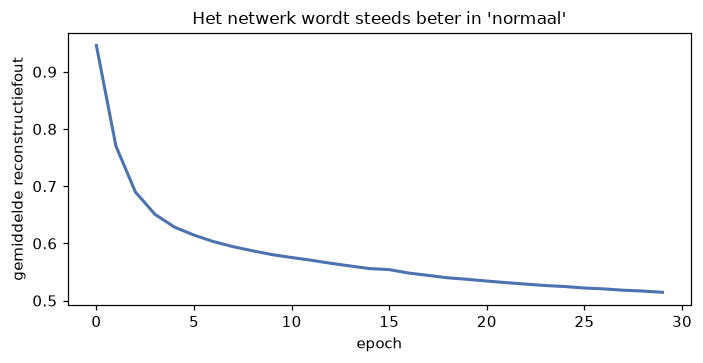

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(geschiedenis, lw=2, color="#4C72B0")
ax.set_xlabel("epoch"); ax.set_ylabel("gemiddelde reconstructiefout")
ax.set_title("Het netwerk wordt steeds beter in 'normaal'", fontsize=11)
plt.tight_layout()
plt.show()

---

## 5. De reconstructiefout als anomaliescore

Nu het moment van de waarheid. We duwen de hele testset — normaal én fraude — door de
autoencoder en meten per transactie hoe ver de reconstructie ernaast zit.

In [10]:
with torch.no_grad():
    reconstructie_test = autoencoder(test_alles)
    # Per transactie: het gemiddelde kwadratische verschil over alle 29 features.
    fout_test = ((reconstructie_test - test_alles) ** 2).mean(dim=1).numpy()

    reconstructie_train = autoencoder(train_normaal)
    fout_train = ((reconstructie_train - train_normaal) ** 2).mean(dim=1).numpy()

resultaat = pd.DataFrame({"fout": fout_test, "fraude": y_test})

print("Mediane reconstructiefout:")
print(f"  normale transacties : {resultaat.loc[resultaat.fraude == 0, 'fout'].median():8.3f}")
print(f"  fraudegevallen      : {resultaat.loc[resultaat.fraude == 1, 'fout'].median():8.3f}")
verhouding = (resultaat.loc[resultaat.fraude == 1, "fout"].median()
              / resultaat.loc[resultaat.fraude == 0, "fout"].median())
print(f"\nFraude reconstrueert {verhouding:.0f}x slechter. Dat is het signaal waar we op jagen.")

Mediane reconstructiefout:
  normale transacties :    0.347
  fraudegevallen      :   11.317

Fraude reconstrueert 33x slechter. Dat is het signaal waar we op jagen.


### De plot waar het om draait

De fouten lopen over enorm verschillende ordes van grootte, dus we zetten de x-as logaritmisch.
Let op de overlap in het midden: **de twee groepen zijn niet netjes gescheiden.** Elke drempel
die je kiest, zit ergens in dat grijze gebied.

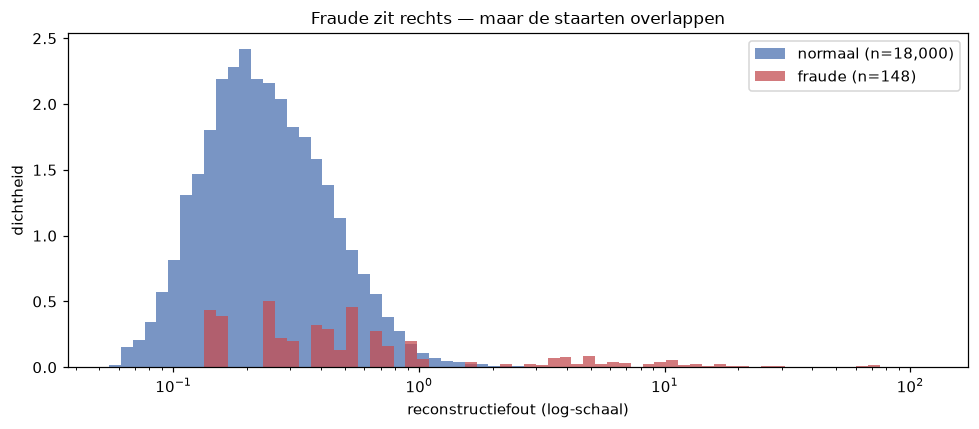

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
randen = np.logspace(np.log10(resultaat.fout.min() + 1e-6), np.log10(resultaat.fout.max()), 70)

ax.hist(resultaat.loc[resultaat.fraude == 0, "fout"], bins=randen, color="#4C72B0",
        alpha=0.75, label=f"normaal (n={(y_test == 0).sum():,})", density=True)
ax.hist(resultaat.loc[resultaat.fraude == 1, "fout"], bins=randen, color="#C44E52",
        alpha=0.75, label=f"fraude (n={(y_test == 1).sum()})", density=True)
ax.set_xscale("log")
ax.set_xlabel("reconstructiefout (log-schaal)")
ax.set_ylabel("dichtheid")
ax.set_title("Fraude zit rechts — maar de staarten overlappen", fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

### Hoe goed is dat eigenlijk?

Twee maten, en het verschil ertussen is belangrijk genoeg om apart te bespreken.

- **ROC-AUC**: als ik één willekeurige fraude en één willekeurige normale transactie pak, hoe
  vaak geeft het model de fraude de hogere score? Prettig getal, maar het houdt geen rekening
  met hoe zeldzaam fraude is.
- **PR-AUC** (average precision): hoeveel van mijn alarmen zijn terecht, over alle drempels heen.
  Bij 0,8% fraude is dit de eerlijke maat — een willekeurig model scoort hier 0,008.

ROC-AUC : 0.9418
PR-AUC  : 0.6256
basislijn voor PR-AUC (willekeurig raden): 0.0082

De autoencoder is dus 77x beter dan gokken.


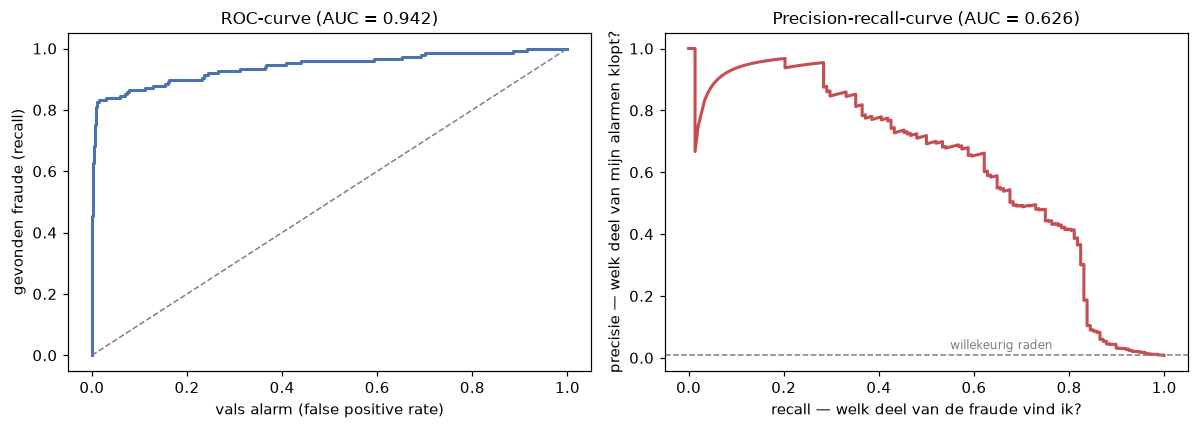

In [12]:
roc = roc_auc_score(y_test, fout_test)
pr  = average_precision_score(y_test, fout_test)

print(f"ROC-AUC : {roc:.4f}")
print(f"PR-AUC  : {pr:.4f}")
print(f"basislijn voor PR-AUC (willekeurig raden): {y_test.mean():.4f}")
print(f"\nDe autoencoder is dus {pr / y_test.mean():.0f}x beter dan gokken.")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_test, fout_test)
a.plot(fpr, tpr, lw=2, color="#4C72B0"); a.plot([0, 1], [0, 1], "--", color="grey", lw=1)
a.set_xlabel("vals alarm (false positive rate)"); a.set_ylabel("gevonden fraude (recall)")
a.set_title(f"ROC-curve (AUC = {roc:.3f})", fontsize=11)

precisie, recall, _ = precision_recall_curve(y_test, fout_test)
b.plot(recall, precisie, lw=2, color="#C44E52")
b.axhline(y_test.mean(), ls="--", color="grey", lw=1)
b.text(0.55, y_test.mean() + 0.02, "willekeurig raden", fontsize=8, color="grey")
b.set_xlabel("recall — welk deel van de fraude vind ik?")
b.set_ylabel("precisie — welk deel van mijn alarmen klopt?")
b.set_title(f"Precision-recall-curve (AUC = {pr:.3f})", fontsize=11)

plt.tight_layout()
plt.show()

---

## 6. Een drempel kiezen

Een score is nog geen beslissing. Ergens moet je zeggen: **boven deze waarde sturen we een
alarm.** En omdat we geen fraudelabels willen gebruiken om die grens te bepalen, kijken we naar
de fouten van de **normale trainingstransacties**: "alarm bij alles wat slechter reconstrueert
dan 99% van wat ik normaal vind."

Die ene keuze bepaalt alles. Laten we hem zichtbaar maken in de enige eenheid die telt voor de
afdeling die de alarmen moet nakijken: **hoeveel fraude vang ik, en hoeveel onzin moet iemand
doorspitten?**

In [13]:
rijen = []
for percentiel in [90, 95, 99, 99.5, 99.9]:
    drempel = np.percentile(fout_train, percentiel)
    voorspeld = (fout_test > drempel).astype(int)
    p, r, _, _ = precision_recall_fscore_support(
        y_test, voorspeld, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, voorspeld).ravel()
    rijen.append({
        "percentiel": percentiel,
        "drempel": round(drempel, 2),
        "gevonden fraude": f"{tp}/{tp + fn}",
        "gemiste fraude": fn,
        "valse alarmen": fp,
        "precisie": round(p, 3),
        "recall": round(r, 3),
    })

tabel = pd.DataFrame(rijen).set_index("percentiel")
display(tabel)

print("Lees de tabel van boven naar beneden: hoe strenger de drempel,")
print("hoe minder vals alarm - maar hoe meer fraude je laat lopen.")

,drempel,gevonden fraude,gemiste fraude,valse alarmen,precisie,recall
percentiel,,,,,,
90.0,0.81,128/148,20,1834,0.065,0.865
95.0,1.10,124/148,24,942,0.116,0.838
99.0,3.28,121/148,27,191,0.388,0.818
99.5,5.48,100/148,48,95,0.513,0.676
99.9,15.60,63/148,85,21,0.750,0.426


Lees de tabel van boven naar beneden: hoe strenger de drempel,
hoe minder vals alarm - maar hoe meer fraude je laat lopen.


**Dit is geen technische keuze maar een zakelijke.** De vraag is niet "welke drempel is het
beste?", maar:

- Wat kost het om een fraudegeval te missen? (het bedrag, plus reputatieschade)
- Wat kost het om een klant onterecht te blokkeren? (een boze klant, een telefoontje)
- Hoeveel alarmen kan je team per dag nakijken?

Een team dat 25 meldingen per dag aankan, kiest een andere drempel dan een team van vijftig
mensen. Laten we er één vastzetten en ernaar kijken.

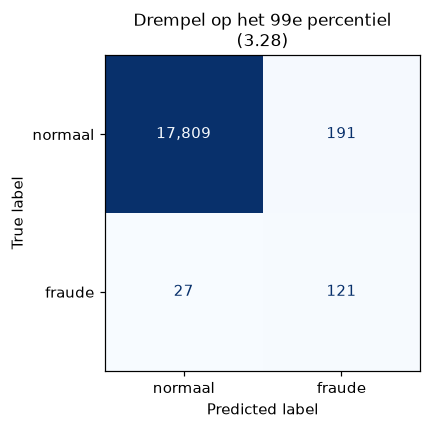

Gevonden      : 121 van de 148 fraudegevallen
Gemist        : 27
Vals alarm    : 191 van de 18000 normale transacties (1.06%)

Een analist moet 312 meldingen nakijken om 121 fraudegevallen te vinden.
Dat is er ongeveer één op de 2.6.


In [14]:
DREMPEL = np.percentile(fout_train, 99)      # verander dit gerust tijdens de les
voorspeld = (fout_test > DREMPEL).astype(int)

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, voorspeld, display_labels=["normaal", "fraude"],
    cmap="Blues", colorbar=False, ax=ax, values_format=",d",
)
ax.set_title(f"Drempel op het 99e percentiel\n({DREMPEL:.2f})", fontsize=11)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, voorspeld).ravel()
print(f"Gevonden      : {tp} van de {tp + fn} fraudegevallen")
print(f"Gemist        : {fn}")
print(f"Vals alarm    : {fp} van de {tn + fp} normale transacties ({fp / (tn + fp):.2%})")
print()
print(f"Een analist moet {tp + fp} meldingen nakijken om {tp} fraudegevallen te vinden.")
print(f"Dat is er ongeveer één op de {(tp + fp) / max(tp, 1):.1f}.")

### Kijk goed naar die tabel

Er staat iets ongemakkelijks in: **op ROC-AUC verliest de autoencoder van allebei de
eenvoudige baselines.** Op PR-AUC wint hij juist duidelijk.

Dat is geen foutje, en het is de belangrijkste les van deze sectie. De twee maten stellen een
andere vraag, en bij 0,8% fraude is PR-AUC de vraag die je echt interesseert: *van de alarmen
die ik afga, hoeveel zijn er terecht?* ROC-AUC laat zich makkelijk vleien door de 59.000
normale transacties die iedereen wel goed classificeert.

De eerlijke conclusie is dus tweeledig:

- **Begin altijd met de simpele baseline.** PCA kost één regel en komt hier verrassend dichtbij.
  Kun je dat niet verslaan, dan heb je je antwoord.
- **Kies je maat vóórdat je de modellen vergelijkt.** Anders kies je achteraf de maat waarmee
  jouw favoriete model wint, en dat is geen onderzoek meer.

---

## 7. Waarom werd deze transactie gemarkeerd?

De reconstructiefout is een gemiddelde over 29 features. Maar niets belet ons om te kijken
**welke** features niet klopten. Dat maakt van een kaal alarm een bruikbare melding voor de
analist die hem moet beoordelen.

*(Wie topic 1 gevolgd heeft, herkent dit: we vragen opnieuw waaróm het model iets vindt.)*

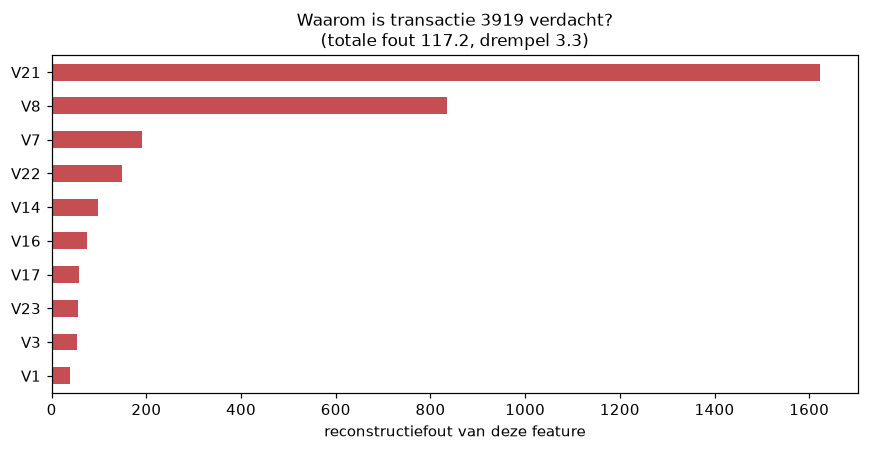

De autoencoder kon deze features niet terugbouwen: daar wijkt de transactie
het sterkst af van alles wat hij als 'normaal' geleerd heeft.


In [16]:
# De fout per feature, in plaats van het gemiddelde.
with torch.no_grad():
    fout_per_feature = ((autoencoder(test_alles) - test_alles) ** 2).numpy()

# We pakken de fraude die het model het zekerst wist.
fraude_indices = np.where(y_test == 1)[0]
gepakt = fraude_indices[np.argmax(fout_test[fraude_indices])]

bijdrage = pd.Series(fout_per_feature[gepakt], index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
bijdrage.head(10)[::-1].plot.barh(ax=ax, color="#C44E52")
ax.set_xlabel("reconstructiefout van deze feature")
ax.set_title(f"Waarom is transactie {gepakt} verdacht?\n"
             f"(totale fout {fout_test[gepakt]:.1f}, drempel {DREMPEL:.1f})", fontsize=11)
plt.tight_layout()
plt.show()

print("De autoencoder kon deze features niet terugbouwen: daar wijkt de transactie")
print("het sterkst af van alles wat hij als 'normaal' geleerd heeft.")

In [17]:
# Doen die features dat bij álle fraude, of alleen bij deze ene transactie?
gemiddelde_fout = pd.DataFrame({
    "bij fraude": fout_per_feature[y_test == 1].mean(axis=0),
    "bij normaal": fout_per_feature[y_test == 0].mean(axis=0),
}, index=X.columns)
gemiddelde_fout["verhouding"] = (gemiddelde_fout["bij fraude"]
                                 / gemiddelde_fout["bij normaal"])

display(gemiddelde_fout.sort_values("verhouding", ascending=False).head(8).round(2))

print("Dezelfde namen komen bovendrijven. Dat zijn de componenten waarin frauduleuze")
print("transacties zich structureel anders gedragen - een patroon dat je aan een")
print("fraudeanalist kunt laten zien, in plaats van alleen een score.")

,bij fraude,bij normaal,verhouding
V17,181.979996,0.28,642.140015
V14,79.720001,0.30,266.179993
V12,74.470001,0.30,247.289993
V10,59.580002,0.31,192.789993
V3,42.900002,0.23,182.800003
V16,62.820000,0.43,145.729996
V7,50.279999,0.50,99.989998
V8,28.370001,0.44,64.910004


Dezelfde namen komen bovendrijven. Dat zijn de componenten waarin frauduleuze
transacties zich structureel anders gedragen - een patroon dat je aan een
fraudeanalist kunt laten zien, in plaats van alleen een score.
